In [1]:
import duckdb

# Connect to DuckDB (in-memory)
con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for trip_distance on the clean dataset...")

# DuckDB query using quantile_cont for median and quartiles (IQR), 
# alongside built-in mean, stddev, and skewness functions.
stats_query = """
WITH clean_filtered AS (
    SELECT trip_distance
    FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
    WHERE 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
        AND trip_distance > 0
        AND fare_amount >= 0
)
SELECT 
    COUNT(trip_distance) AS total_valid_trips,
    AVG(trip_distance) AS mean_val,
    QUANTILE_CONT(trip_distance, 0.5) AS median_val,
    STDDEV(trip_distance) AS std_val,
    QUANTILE_CONT(trip_distance, 0.75) - QUANTILE_CONT(trip_distance, 0.25) AS iqr_val,
    SKEWNESS(trip_distance) AS skewness_val
FROM clean_filtered;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for trip_distance ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for trip_distance on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for trip_distance ---
 total_valid_trips  mean_val  median_val    std_val  iqr_val  skewness_val
          44186099  6.587813        1.89 616.246632     2.63    254.705177


Extracting a representative sample of clean trip distances from 2025 data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 499,506 sampled records for plotting.
Generating trip distance distribution plot...


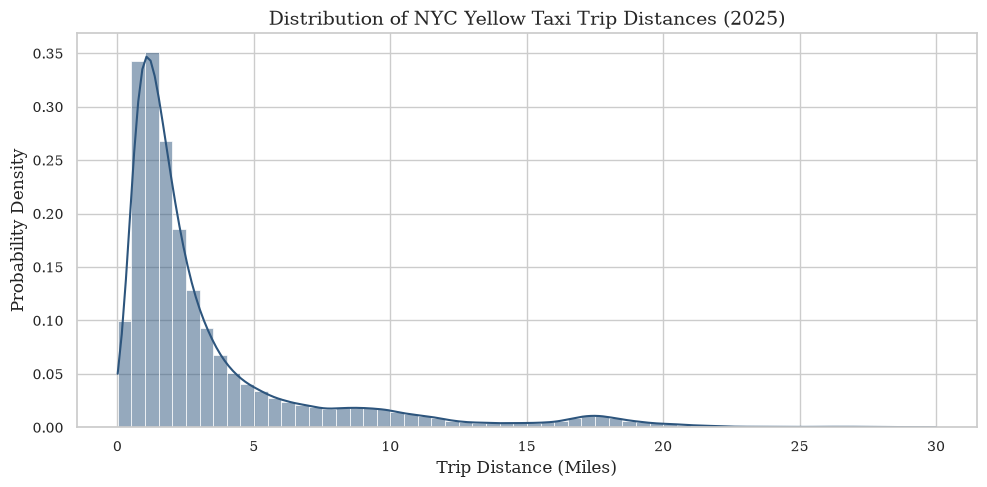

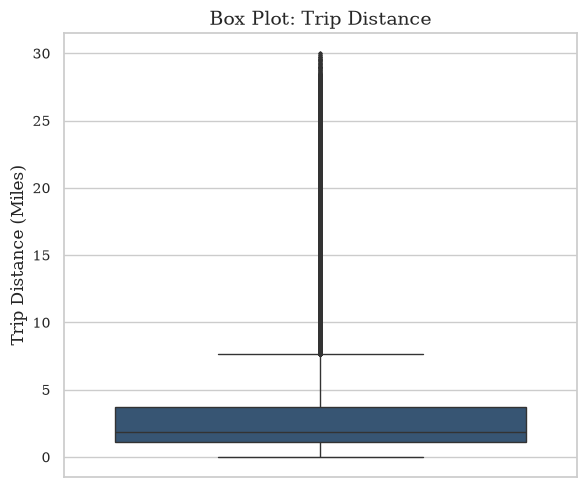

Plot successfully generated and saved to '../reports/figures/trip_distance_distribution.png'!


In [ ]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for professional reports
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("Extracting a representative sample of clean trip distances from 2025 data...")

# Query clean data, capping at 30 miles for visualization clarity, and taking a random sample of 500k rows
query = """
SELECT trip_distance
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND trip_distance <= 30
    AND fare_amount >= 0
USING SAMPLE 500000;
"""

df_dist = con.execute(query).df()
con.close()

print(f"Loaded {len(df_dist):,} sampled records for plotting.")

print("Generating trip distance distribution plot...")
plt.figure(figsize=(10, 5))

# Plot histogram with a Kernel Density Estimate (KDE) curve
ax = sns.histplot(
    df_dist['trip_distance'], 
    bins=60, 
    kde=True, 
    color='#2D557D', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Trip Distances (2025)')
plt.xlabel('Trip Distance (Miles)')
plt.ylabel('Probability Density')

# Save figure for your LaTeX report
plt.savefig('../reports/figures/trip_distance_distribution.png', dpi=300)
plt.show()

print("Plot successfully generated and saved to '../reports/figures/trip_distance_distribution.png'!")

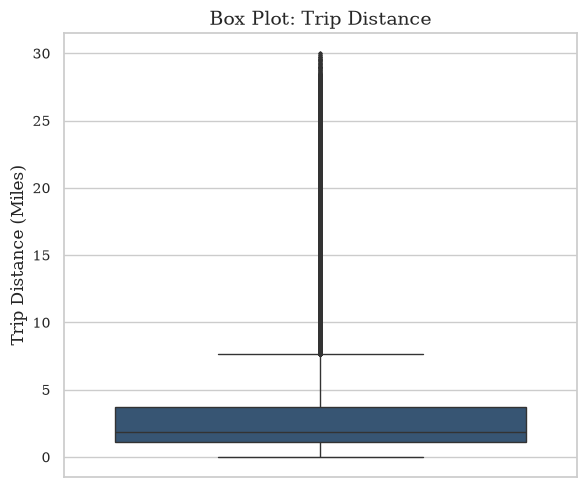

In [18]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_dist['trip_distance'], color='#2D557D', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Trip Distance')
plt.ylabel('Trip Distance (Miles)')
plt.savefig('../reports/figures/trip_distance_boxplot.png', dpi=300)
plt.show()

In [3]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for fare_amount on the clean dataset...")

stats_query = """
WITH clean_filtered AS (
    SELECT fare_amount
    FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
    WHERE 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
        AND trip_distance > 0
        AND fare_amount >= 0
)
SELECT 
    COUNT(fare_amount) AS total_valid_trips,
    AVG(fare_amount) AS mean_val,
    QUANTILE_CONT(fare_amount, 0.5) AS median_val,
    STDDEV(fare_amount) AS std_val,
    QUANTILE_CONT(fare_amount, 0.75) - QUANTILE_CONT(fare_amount, 0.25) AS iqr_val,
    SKEWNESS(fare_amount) AS skewness_val
FROM clean_filtered;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for fare_amount ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for fare_amount on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for fare_amount ---
 total_valid_trips  mean_val  median_val    std_val  iqr_val  skewness_val
          44186099 20.062662        14.2 149.641468    14.02   4824.798606


Extracting sampled clean fare amounts for plotting...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 498,485 sampled records. Generating plot...


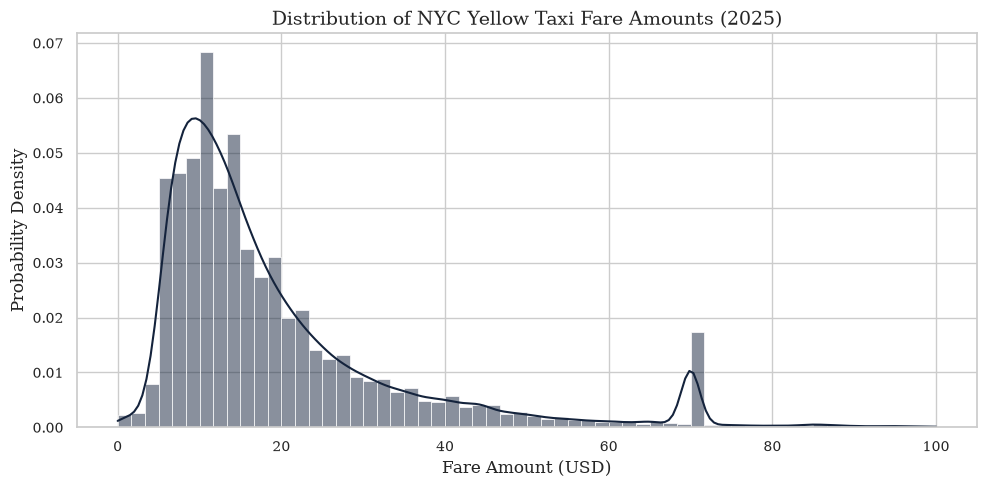

Plot saved to '../reports/figures/fare_amount_distribution.png'!


In [19]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Extracting sampled clean fare amounts for plotting...")
query = """
SELECT fare_amount
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
    AND fare_amount <= 100
USING SAMPLE 500000;
"""

df_fare = con.execute(query).df()
con.close()

print(f"Loaded {len(df_fare):,} sampled records. Generating plot...")

plt.figure(figsize=(10, 5))
ax = sns.histplot(
    df_fare['fare_amount'], 
    bins=60, 
    kde=True, 
    color='#14233C', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Fare Amounts (2025)')
plt.xlabel('Fare Amount (USD)')
plt.ylabel('Probability Density')

plt.savefig('../reports/figures/fare_amount_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/fare_amount_distribution.png'!")

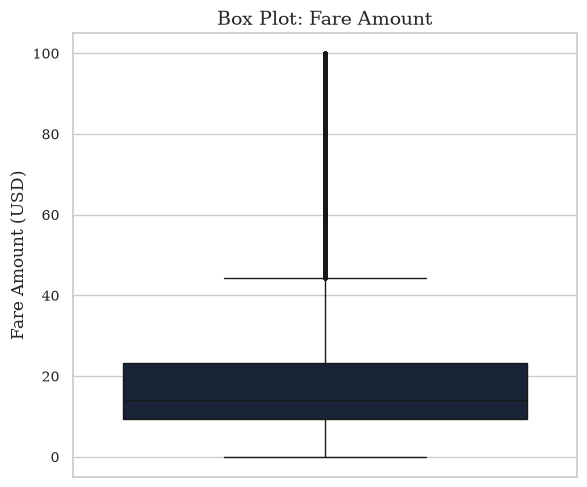

In [20]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_fare['fare_amount'], color='#14233C', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Fare Amount')
plt.ylabel('Fare Amount (USD)')
plt.savefig('../reports/figures/fare_amount_boxplot.png', dpi=300)
plt.show()

In [5]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for cbd_congestion_fee on the clean dataset...")

stats_query = """
WITH clean_filtered AS (
    SELECT cbd_congestion_fee
    FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
    WHERE 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
        AND trip_distance > 0
        AND fare_amount >= 0
)
SELECT 
    COUNT(cbd_congestion_fee) AS total_valid_trips,
    AVG(cbd_congestion_fee) AS mean_val,
    QUANTILE_CONT(cbd_congestion_fee, 0.5) AS median_val,
    STDDEV(cbd_congestion_fee) AS std_val,
    QUANTILE_CONT(cbd_congestion_fee, 0.75) - QUANTILE_CONT(cbd_congestion_fee, 0.25) AS iqr_val,
    SKEWNESS(cbd_congestion_fee) AS skewness_val
FROM clean_filtered;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for cbd_congestion_fee ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for cbd_congestion_fee on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for cbd_congestion_fee ---
 total_valid_trips  mean_val  median_val  std_val  iqr_val  skewness_val
          44186099  0.547504        0.75 0.333062     0.75     -1.037914


Aggregating cbd_congestion_fee frequencies across 2025 data...
Generating CBD congestion fee distribution plot...


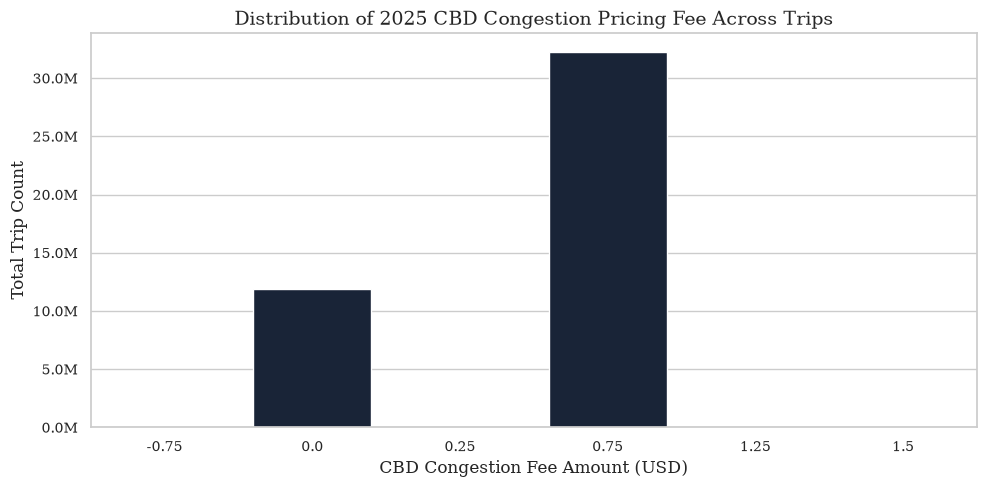

Plot saved to '../reports/figures/cbd_congestion_fee_distribution.png'!


In [21]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Aggregating cbd_congestion_fee frequencies across 2025 data...")
query = """
SELECT 
    COALESCE(cbd_congestion_fee, 0.0) AS fee_amount,
    COUNT(*) AS trip_count
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
GROUP BY fee_amount
ORDER BY fee_amount;
"""

df_cbd = con.execute(query).df()
con.close()

print("Generating CBD congestion fee distribution plot...")
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x='fee_amount',
    y='trip_count',
    data=df_cbd,
    color='#14233C'
)

plt.title('Distribution of 2025 CBD Congestion Pricing Fee Across Trips')
plt.xlabel('CBD Congestion Fee Amount (USD)')
plt.ylabel('Total Trip Count')

# Format y-axis in millions
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))

plt.savefig('../reports/figures/cbd_congestion_fee_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/cbd_congestion_fee_distribution.png'!")

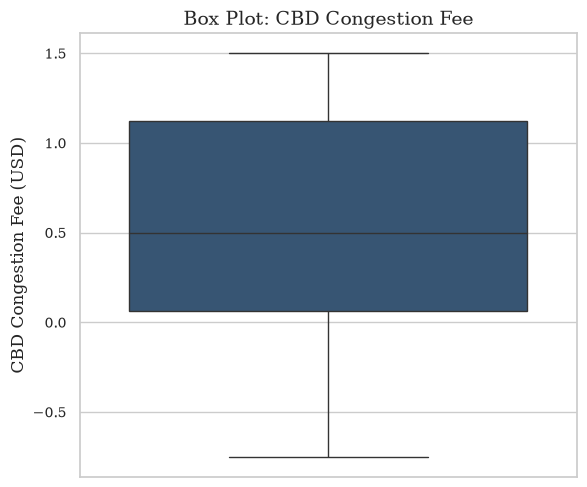

In [25]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_cbd['fee_amount'], color='#2D557D', fliersize=1.5, linewidth=1)
plt.title('Box Plot: CBD Congestion Fee')
plt.ylabel('CBD Congestion Fee (USD)')
plt.savefig('../reports/figures/cbd_congestion_fee_boxplot.png', dpi=300)
plt.show()

In [7]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for passenger_count on the clean dataset...")

stats_query = """
WITH clean_filtered AS (
    SELECT passenger_count
    FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
    WHERE 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
        AND trip_distance > 0
        AND fare_amount >= 0
        AND passenger_count IS NOT NULL
)
SELECT 
    COUNT(passenger_count) AS total_valid_trips,
    MODE(passenger_count) AS mode_val,
    AVG(passenger_count::DOUBLE) AS mean_val,
    QUANTILE_CONT(passenger_count, 0.5) AS median_val,
    STDDEV(passenger_count::DOUBLE) AS std_val,
    QUANTILE_CONT(passenger_count, 0.75) - QUANTILE_CONT(passenger_count, 0.25) AS iqr_val,
    SKEWNESS(passenger_count::DOUBLE) AS skewness_val
FROM clean_filtered;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for passenger_count ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for passenger_count on the clean dataset...

--- Statistical Summary for passenger_count ---
 total_valid_trips  mode_val  mean_val  median_val  std_val  iqr_val  skewness_val
          35336648         1  1.292533         1.0 0.726834      0.0      2.967185


Aggregating passenger count frequencies across 2025 data...
Generating passenger count distribution plot...


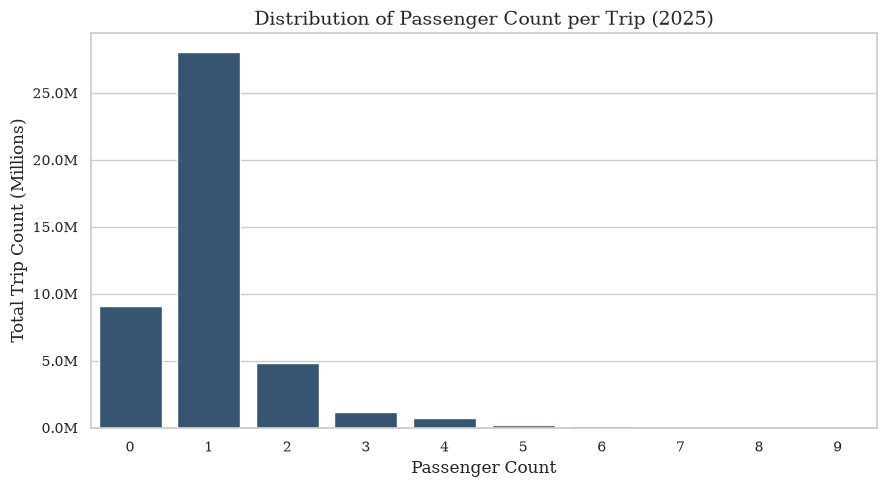

Plot saved to '../reports/figures/passenger_count_distribution.png'!


In [8]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Aggregating passenger count frequencies across 2025 data...")
query = """
SELECT 
    COALESCE(passenger_count, 0) AS p_count,
    COUNT(*) AS trip_count
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
GROUP BY p_count
ORDER BY p_count;
"""

df_pass = con.execute(query).df()
con.close()

print("Generating passenger count distribution plot...")
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x='p_count',
    y='trip_count',
    data=df_pass,
    color='#2D557D'
)

plt.title('Distribution of Passenger Count per Trip (2025)')
plt.xlabel('Passenger Count')
plt.ylabel('Total Trip Count (Millions)')

# Format y-axis in millions
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))

plt.savefig('../reports/figures/passenger_count_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/passenger_count_distribution.png'!")

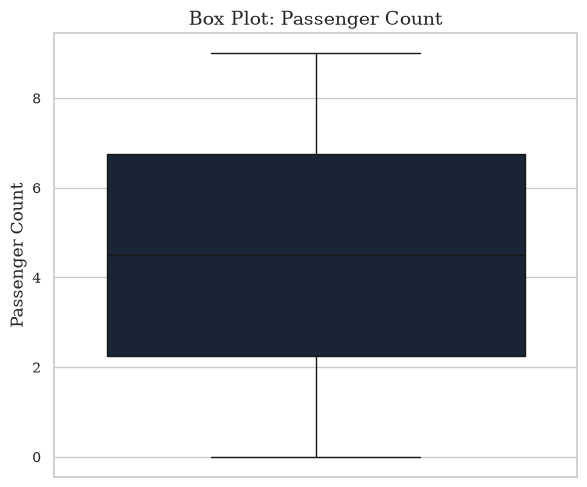

In [27]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_pass['p_count'], color='#14233C', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Passenger Count')
plt.ylabel('Passenger Count')
plt.savefig('../reports/figures/passenger_count_boxplot.png', dpi=300)
plt.show()

In [9]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for tip_amount on the clean dataset...")

stats_query = """
WITH clean_filtered AS (
    SELECT tip_amount
    FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
    WHERE 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
        AND trip_distance > 0
        AND fare_amount >= 0
        AND tip_amount >= 0
)
SELECT 
    COUNT(tip_amount) AS total_valid_trips,
    AVG(tip_amount) AS mean_val,
    QUANTILE_CONT(tip_amount, 0.5) AS median_val,
    STDDEV(tip_amount) AS std_val,
    QUANTILE_CONT(tip_amount, 0.75) - QUANTILE_CONT(tip_amount, 0.25) AS iqr_val,
    SKEWNESS(tip_amount) AS skewness_val
FROM clean_filtered;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for tip_amount ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for tip_amount on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for tip_amount ---
 total_valid_trips  mean_val  median_val  std_val  iqr_val  skewness_val
          44186097   3.04368        2.39 3.965092     4.07      4.576163


Extracting sampled clean tip amounts for plotting...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 499,585 sampled records. Generating plot...


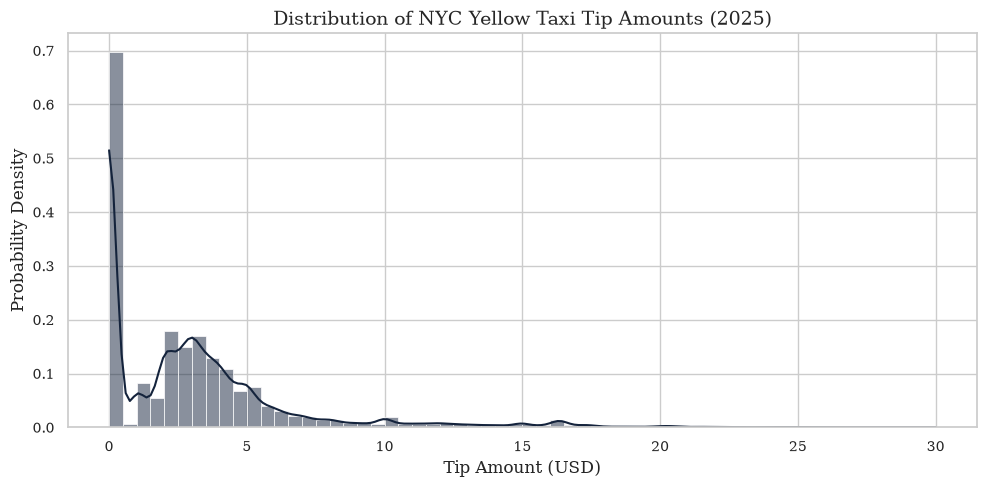

Plot saved to '../reports/figures/tip_amount_distribution.png'!


In [29]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Extracting sampled clean tip amounts for plotting...")
query = """
SELECT tip_amount
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
    AND tip_amount >= 0
    AND tip_amount <= 30
USING SAMPLE 500000;
"""

df_tip = con.execute(query).df()
con.close()

print(f"Loaded {len(df_tip):,} sampled records. Generating plot...")

plt.figure(figsize=(10, 5))
ax = sns.histplot(
    df_tip['tip_amount'], 
    bins=60, 
    kde=True, 
    color='#14233C', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Tip Amounts (2025)')
plt.xlabel('Tip Amount (USD)')
plt.ylabel('Probability Density')

plt.savefig('../reports/figures/tip_amount_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/tip_amount_distribution.png'!")

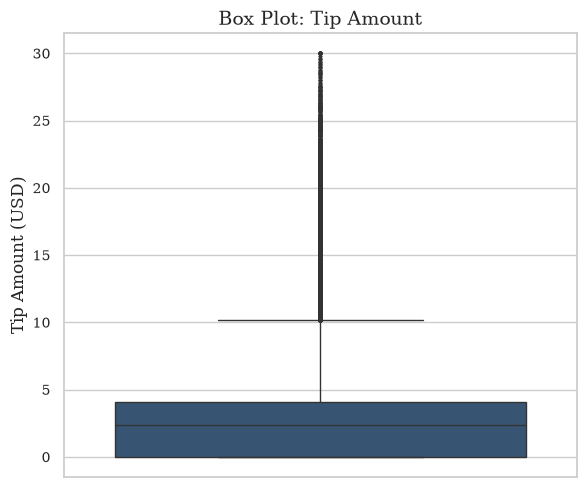

In [30]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_tip['tip_amount'], color='#2D557D', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Tip Amount')
plt.ylabel('Tip Amount (USD)')
plt.savefig('../reports/figures/tip_amount_boxplot.png', dpi=300)
plt.show()

In [11]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing frequency distribution and summary statistics for payment_type...")

stats_query = """
WITH clean_filtered AS (
    SELECT payment_type
    FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
    WHERE 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
        AND trip_distance > 0
        AND fare_amount >= 0
        AND payment_type IS NOT NULL
)
SELECT 
    payment_type,
    COUNT(*) AS trip_count,
    (COUNT(*) * 100.0 / SUM(COUNT(*)) OVER()) AS percentage_share
FROM clean_filtered
GROUP BY payment_type
ORDER BY trip_count DESC;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Payment Type Breakdown ---")
print(df_stats.to_string(index=False))

Computing frequency distribution and summary statistics for payment_type...

--- Payment Type Breakdown ---
 payment_type  trip_count  percentage_share
            1    30338719         68.661230
            0     8849451         20.027681
            2     4302282          9.736732
            4      533797          1.208065
            3      161849          0.366289
            5           1          0.000002


Aggregating payment type frequencies across 2025 data...
Generating payment type distribution plot...


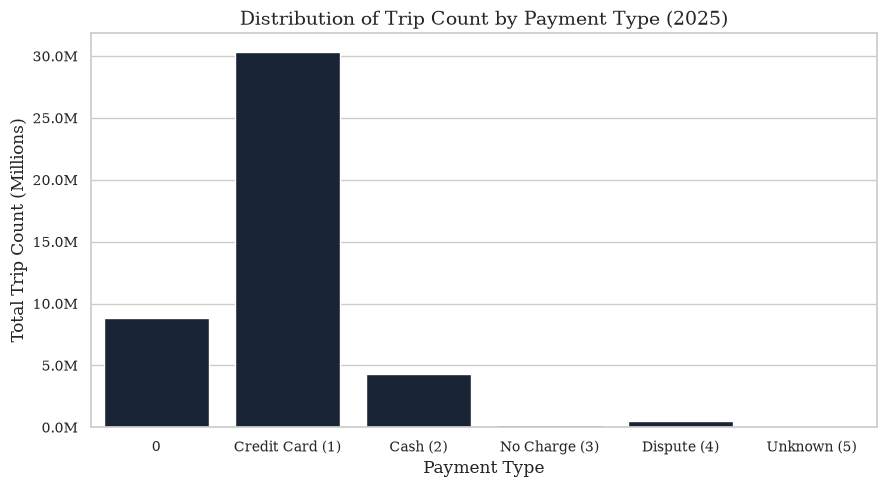

Plot saved to '../reports/figures/payment_type_distribution.png'!


In [12]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Aggregating payment type frequencies across 2025 data...")
query = """
SELECT 
    CAST(payment_type AS VARCHAR) AS p_type,
    COUNT(*) AS trip_count
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
    AND payment_type IS NOT NULL
GROUP BY p_type
ORDER BY p_type;
"""

df_pay = con.execute(query).df()
con.close()

# Map TLC codes to descriptive labels for better visualization
code_mapping = {
    '1': 'Credit Card (1)',
    '2': 'Cash (2)',
    '3': 'No Charge (3)',
    '4': 'Dispute (4)',
    '5': 'Unknown (5)',
    '6': 'Voided (6)'
}
df_pay['payment_label'] = df_pay['p_type'].map(code_mapping).fillna(df_pay['p_type'])

print("Generating payment type distribution plot...")
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x='payment_label',
    y='trip_count',
    data=df_pay,
    color='#14233C'
)

plt.title('Distribution of Trip Count by Payment Type (2025)')
plt.xlabel('Payment Type')
plt.ylabel('Total Trip Count (Millions)')

# Format y-axis in millions
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))

plt.savefig('../reports/figures/payment_type_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/payment_type_distribution.png'!")

Extracting a representative sample of clean trip durations from processed data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 489,764 sampled records for plotting.
Generating trip duration distribution plot...


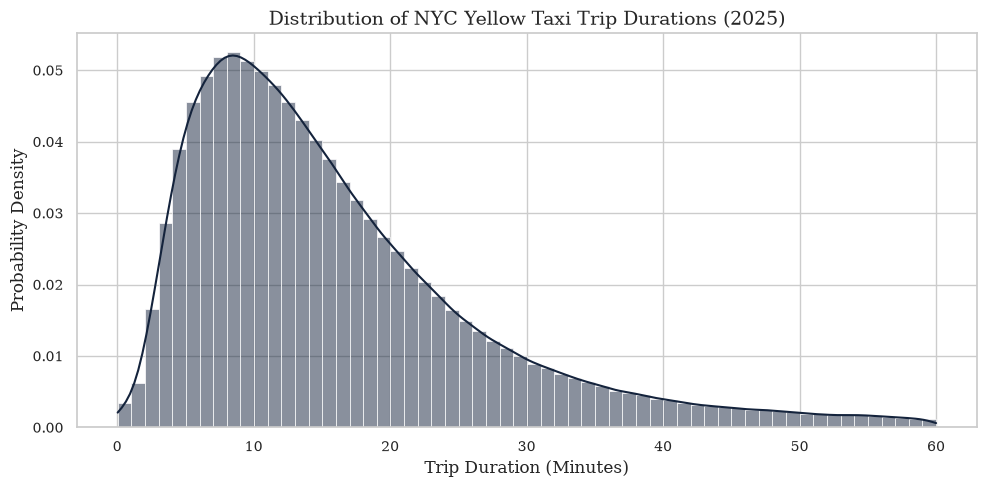

Plot successfully generated and saved to '../reports/figures/trip_duration_distribution.png'!


In [31]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for professional reports
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("Extracting a representative sample of clean trip durations from processed data...")

# Query processed data, calculating duration in minutes, capping at 60 mins for visualization
query = """
SELECT 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration_minutes
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 <= 60
USING SAMPLE 500000;
"""

df_duration = con.execute(query).df()
con.close()

print(f"Loaded {len(df_duration):,} sampled records for plotting.")

print("Generating trip duration distribution plot...")
plt.figure(figsize=(10, 5))

# Plot histogram with a Kernel Density Estimate (KDE) curve
ax = sns.histplot(
    df_duration['trip_duration_minutes'], 
    bins=60, 
    kde=True, 
    color='#14233C', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Trip Durations (2025)')
plt.xlabel('Trip Duration (Minutes)')
plt.ylabel('Probability Density')

# Save figure for your LaTeX report
plt.savefig('../reports/figures/trip_duration_distribution.png', dpi=300)
plt.show()

print("Plot successfully generated and saved to '../reports/figures/trip_duration_distribution.png'!")

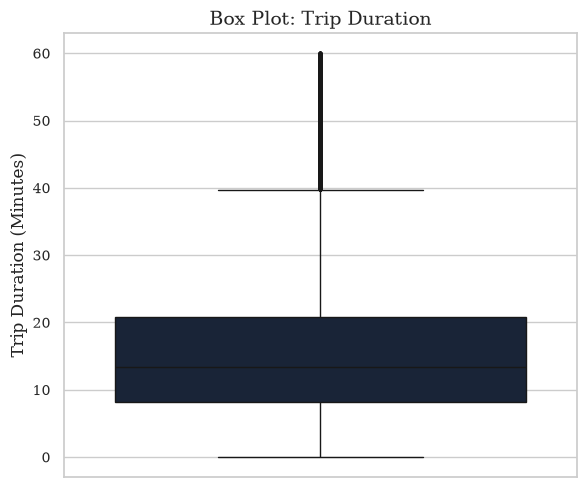

In [33]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_duration['trip_duration_minutes'], color='#14233C', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Trip Duration')
plt.ylabel('Trip Duration (Minutes)')
plt.savefig('../reports/figures/trip_duration_boxplot.png', dpi=300)
plt.show()